# Regression Track — Notebook 04
# 6. Outlier Analysis

**Input:** `artifacts/reg_03_eda.joblib`
**Output:** `artifacts/reg_04_cleaned.joblib`

---

### Purpose and guiding principle

The temptation with outliers is to run an IQR filter over every column and
delete whatever it flags. That is almost always the wrong thing to do, and on
this dataset it would be actively harmful: the "outliers" in
`Rented Bike Count` are the busiest hours of the year, which are precisely the
hours the operator most needs a forecast for. Deleting them would produce a
model that looks excellent on paper and fails exactly when it matters.

So the principle here is:

> **An outlier is only a problem if it is an error. A statistically extreme
> value that is physically real is data, not noise.**

For every flagged group we ask three questions in order:

1. **Is it an error or a genuine observation?**
2. **Does it need treatment at all?**
3. **If so, what treatment, and what is the cost of that treatment?**

This notebook also executes the one row-removal decision recorded in
Notebook 02 (the non-functioning hours), because all row-level changes belong
in one place where a reviewer can find them.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    iqr_outlier_summary,
    load_artifact,
    save_artifact,
    save_figure,
    save_table,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

bike_df = load_artifact("reg_03_eda")

TARGET = "Rented Bike Count"
NUMERIC_FEATURES = [
    "Hour", "Temperature(°C)", "Humidity(%)", "Wind speed (m/s)",
    "Visibility (10m)", "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)", "Rainfall(mm)", "Snowfall (cm)",
]

print(f"\nStarting shape: {bike_df.shape}")

[loaded] artifacts/reg_03_eda.joblib

Starting shape: (8760, 14)


---
## 6.1 Step one: remove structurally invalid rows

Notebook 02 established that on all 295 hours with `Functioning Day == "No"`
the target is exactly 0, with zero variance. These rows describe a closed
system, not low demand. We remove them here and record the effect.

In [2]:
before = len(bike_df)
non_functioning = bike_df[bike_df["Functioning Day"] == "No"]

section("REMOVING NON-FUNCTIONING HOURS")
print(f"Rows before                                  : {before:,}")
print(f"Rows with Functioning Day == 'No'            : {len(non_functioning):,}")
print(f"  ...of which target == 0                    : {int((non_functioning[TARGET] == 0).sum()):,}")
print(f"  ...target mean / std on those rows         : "
      f"{non_functioning[TARGET].mean():.1f} / {non_functioning[TARGET].std():.1f}")

df = bike_df[bike_df["Functioning Day"] == "Yes"].copy()
df = df.drop(columns=["Functioning Day"]).reset_index(drop=True)

print(f"\nRows after                                   : {len(df):,} "
      f"({100 * len(df) / before:.2f}% retained)")
print(f"Zero-count hours remaining                   : {int((df[TARGET] == 0).sum())}")
print(f"'Functioning Day' column dropped (now constant, carries no information)")
print(f"Shape now                                    : {df.shape}")

REMOVING NON-FUNCTIONING HOURS
Rows before                                  : 8,760
Rows with Functioning Day == 'No'            : 295
  ...of which target == 0                    : 295
  ...target mean / std on those rows         : 0.0 / 0.0

Rows after                                   : 8,465 (96.63% retained)
Zero-count hours remaining                   : 0
'Functioning Day' column dropped (now constant, carries no information)
Shape now                                    : (8465, 13)


**Justification.** This is not outlier removal — it is removing rows that do
not belong to the population we are modelling. The question we are answering
is "how many bikes will people rent", which presupposes that bikes are
available to rent. Including deterministic zeros would let every model gain
apparent accuracy from an administrative rule while learning nothing about
demand, and would inflate R² in a way that does not transfer to the operator's
real decision.

The `Functioning Day` column is then dropped because after the filter it takes
a single value for every remaining row. A constant column has zero variance
and therefore zero predictive content; keeping it would just add a useless
one-hot column.

**Cost of this decision:** we lose 3.37% of rows. The model will have nothing
to say about system-closure days — an acceptable limitation, since those are
known in advance from the operator's own schedule rather than predicted.

---
## 6.2 Boxplots of every numerical variable

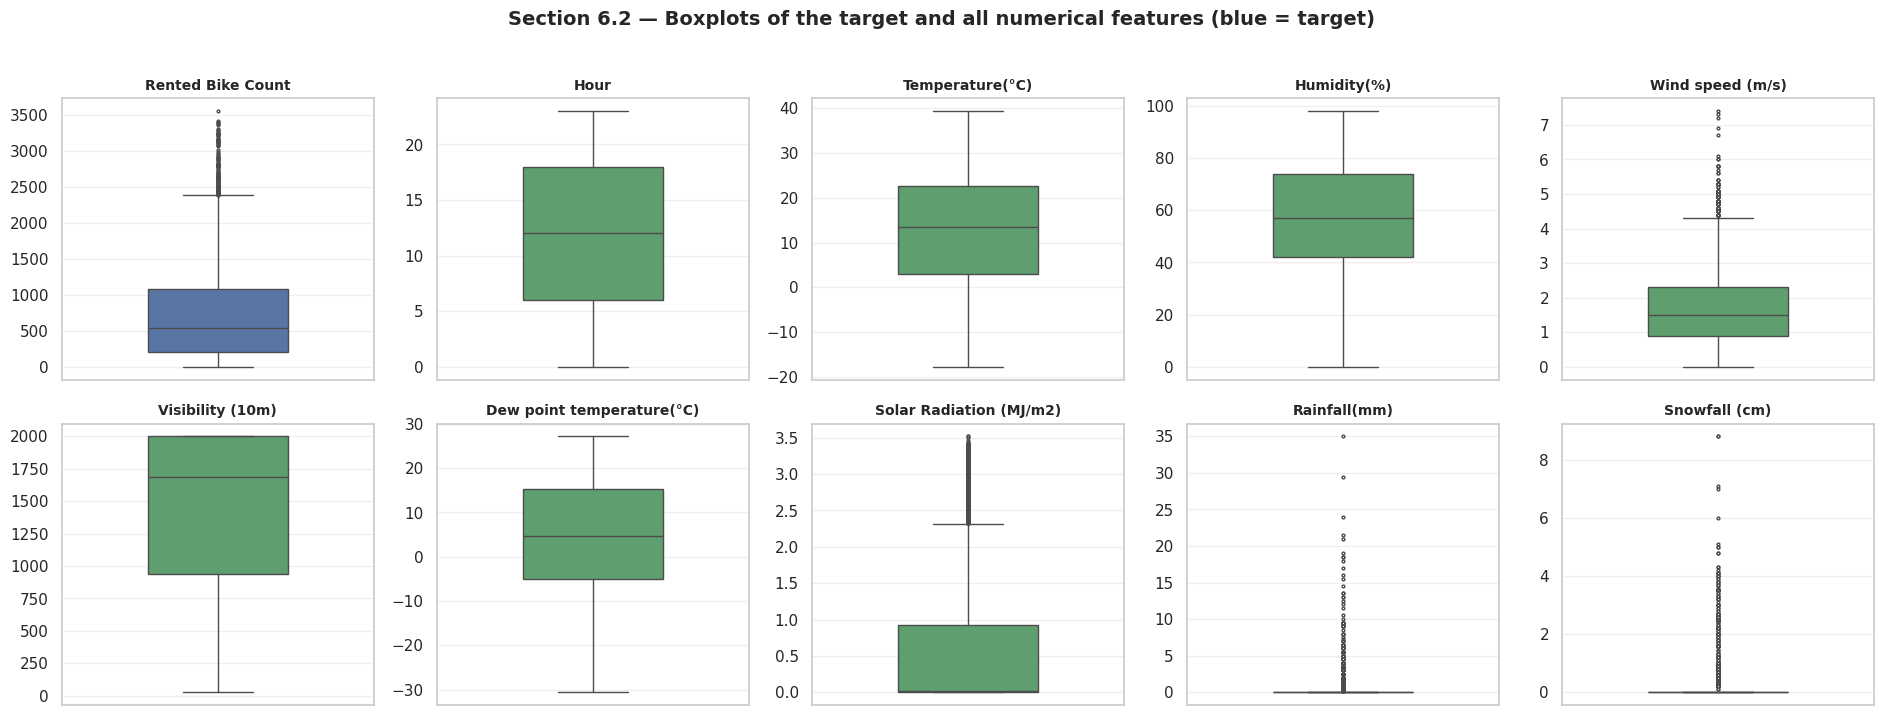

In [3]:
plot_cols = [TARGET] + NUMERIC_FEATURES
fig, axes = plt.subplots(2, 5, figsize=(19, 7))
axes = axes.ravel()

for ax, col in zip(axes, plot_cols):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0" if col == TARGET else "#55A868",
                width=0.45, fliersize=2)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
for ax in axes[len(plot_cols):]:
    ax.set_visible(False)

fig.suptitle("Section 6.2 — Boxplots of the target and all numerical features "
             "(blue = target)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_outlier_boxplots", fig)
plt.show()

**Observation.** Visually, three different situations appear:

* `Temperature`, `Dew point`, `Humidity` and `Hour` have compact boxes with
  few or no flagged points.
* `Rented Bike Count`, `Wind speed` and `Solar Radiation` show a moderate
  number of points above the upper whisker.
* `Rainfall`, `Snowfall` and (in the opposite direction) `Visibility` look
  pathological — the box is collapsed almost to a line with a dense cloud of
  flagged points.

**Interpretation.** The third group is the important one, and it is a
limitation of the boxplot rather than a finding about the data. Tukey's rule
defines outliers as points beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR. When a
variable is zero more than 75% of the time, both Q1 and Q3 equal zero, so the
IQR is zero, both fences collapse onto zero, and **every non-zero value is
automatically flagged as an outlier**. The method is not detecting anomalies
in `Rainfall`; it is detecting that it rains sometimes. This is exactly why an
automatic IQR filter must not be applied blindly.

---
## 6.3 Quantifying it: IQR analysis

In [4]:
iqr_report = iqr_outlier_summary(df, plot_cols)
save_table(iqr_report, "reg_outlier_iqr_report")
iqr_report

[saved]  outputs/reg_outlier_iqr_report.csv


,Feature,Q1,Q3,IQR,Lower fence,Upper fence,Outliers,Outlier %,Min,Max
0,Solar Radiation (MJ/m2),0.0,0.93,0.93,-1.395,2.325,620,7.32,0.0,3.52
1,Rainfall(mm),0.0,0.00,0.00,0.000,0.000,516,6.10,0.0,35.00
2,Snowfall (cm),0.0,0.00,0.00,0.000,0.000,443,5.23,0.0,8.80
3,Wind speed (m/s),0.9,2.30,1.40,-1.200,4.400,154,1.82,0.0,7.40
4,Rented Bike Count,214.0,1084.00,870.00,-1091.000,2389.000,152,1.80,2.0,3556.00
5,Hour,6.0,18.00,12.00,-12.000,36.000,0,0.00,0.0,23.00
6,Visibility (10m),935.0,2000.00,1065.00,-662.500,3597.500,0,0.00,27.0,2000.00
7,Humidity(%),42.0,74.00,32.00,-6.000,122.000,0,0.00,0.0,98.00
8,Temperature(°C),3.0,22.70,19.70,-26.550,52.250,0,0.00,-17.8,39.40
9,Dew point temperature(°C),-5.1,15.20,20.30,-35.550,45.650,0,0.00,-30.6,27.20


**Observation.** The table confirms the reading above. `Rainfall` and
`Snowfall` have IQR = 0 and fences of [0, 0], so their "outlier" percentages
simply restate how often it rains or snows. `Rented Bike Count` flags a
meaningful but modest share of rows, all in the upper tail.

**Interpretation.** IQR is only a sensible detector for the roughly
symmetric, non-zero-inflated variables (`Temperature`, `Humidity`,
`Dew point`, `Wind speed`). For the rest it is measuring the wrong thing. We
therefore investigate the target's flagged values directly rather than trusting
a single automatic rule.

---
## 6.4 Percentile analysis of the target

A second, independent view: where does the mass of the distribution sit, and
how extreme is the extreme tail really?

In [5]:
percentiles = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.0]
pct_table = pd.DataFrame({
    "Percentile": [f"{p:.1%}" for p in percentiles],
    "Rented Bike Count": [round(df[TARGET].quantile(p), 1) for p in percentiles],
})

q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
z_scores = np.abs(stats.zscore(df[TARGET]))

section("TARGET PERCENTILES")
print(pct_table.to_string(index=False))

section("HOW MANY POINTS DO DIFFERENT RULES FLAG?")
print(f"Tukey IQR (> {upper_fence:,.0f})          : {int((df[TARGET] > upper_fence).sum()):>5,} rows "
      f"({100 * (df[TARGET] > upper_fence).mean():.2f}%)")
print(f"Z-score > 3                        : {int((z_scores > 3).sum()):>5,} rows "
      f"({100 * (z_scores > 3).mean():.2f}%)")
print(f"Above the 99th percentile          : {int((df[TARGET] > df[TARGET].quantile(0.99)).sum()):>5,} rows")
print(f"Maximum observed value             : {df[TARGET].max():,}")
print(f"Ratio of max to 99th percentile    : {df[TARGET].max() / df[TARGET].quantile(0.99):.2f}×")

TARGET PERCENTILES
Percentile  Rented Bike Count
      0.1%                4.0
      1.0%               17.0
      5.0%               49.0
     25.0%              214.0
     50.0%              542.0
     75.0%             1084.0
     90.0%             1696.6
     95.0%             2058.8
     99.0%             2556.4
     99.5%             2834.1
     99.9%             3267.3
    100.0%             3556.0
HOW MANY POINTS DO DIFFERENT RULES FLAG?
Tukey IQR (> 2,389)          :   152 rows (1.80%)
Z-score > 3                        :    63 rows (0.74%)
Above the 99th percentile          :    85 rows
Maximum observed value             : 3,556
Ratio of max to 99th percentile    : 1.39×


**Observation.** The maximum (3,556) is only about 1.4× the 99th percentile,
and the distribution climbs smoothly through the upper percentiles rather than
jumping. There is no isolated cluster sitting far away from everything else.

**Interpretation.** This is the signature of a **heavy tail**, not of
contamination. A data-entry error typically looks like a single value orders
of magnitude away from its neighbours (a count of 35,560, say). Nothing here
behaves that way. The extreme values are continuous with the rest of the
distribution.

---
## 6.5 Are the extreme hours explainable? (the decisive test)

The strongest evidence that an extreme value is genuine is that it occurs
under conditions where we would *expect* extreme behaviour. If the
highest-demand hours turn out to be scattered randomly across the clock and
the calendar, they are probably noise. If they cluster in warm evening
commutes, they are real.

In [6]:
flagged = df[df[TARGET] > upper_fence]

section(f"PROFILE OF THE {len(flagged):,} HOURS ABOVE THE IQR UPPER FENCE")
print("Distribution by hour of day (top 8 hours):")
print(flagged["Hour"].value_counts().head(8).to_string())
print("\nDistribution by season:")
print(flagged["Seasons"].value_counts().to_string())
print("\nWeather during flagged hours vs all other hours:")
comparison = pd.DataFrame({
    "Flagged (high demand)": flagged[["Temperature(°C)", "Humidity(%)",
                                      "Rainfall(mm)", "Solar Radiation (MJ/m2)"]].mean(),
    "All other hours": df[~df.index.isin(flagged.index)][
        ["Temperature(°C)", "Humidity(%)", "Rainfall(mm)", "Solar Radiation (MJ/m2)"]].mean(),
}).round(2)
print(comparison.to_string())

PROFILE OF THE 152 HOURS ABOVE THE IQR UPPER FENCE
Distribution by hour of day (top 8 hours):
Hour
18    86
19    34
20    15
17     7
21     4
8      4
16     2

Distribution by season:
Seasons
Summer    85
Autumn    35
Spring    32

Weather during flagged hours vs all other hours:
                         Flagged (high demand)  All other hours
Temperature(°C)                          24.31            12.56
Humidity(%)                              50.09            58.29
Rainfall(mm)                              0.00             0.15
Solar Radiation (MJ/m2)                   0.59             0.57


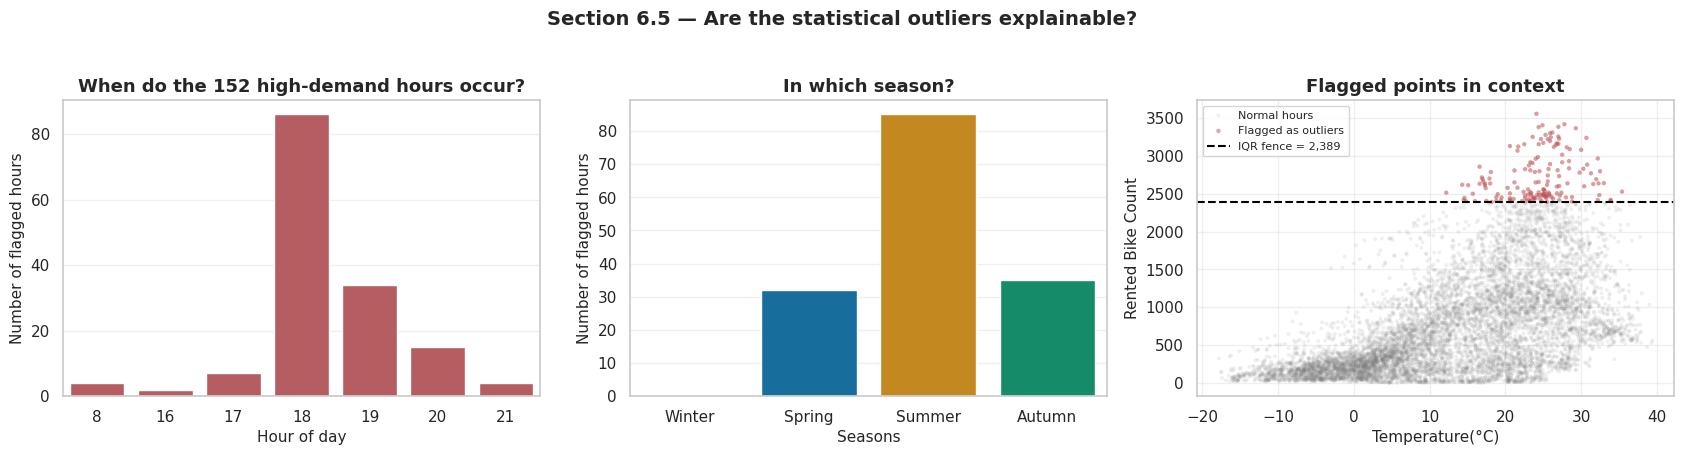

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

sns.countplot(data=flagged, x="Hour", color="#C44E52", ax=axes[0])
axes[0].set_title(f"When do the {len(flagged)} high-demand hours occur?")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Number of flagged hours")

season_order = ["Winter", "Spring", "Summer", "Autumn"]
sns.countplot(data=flagged, x="Seasons", order=season_order,
              hue="Seasons", legend=False, palette="colorblind", ax=axes[1])
axes[1].set_title("In which season?")
axes[1].set_ylabel("Number of flagged hours")

axes[2].scatter(df["Temperature(°C)"], df[TARGET], alpha=0.12, s=8,
                edgecolor="none", color="grey", label="Normal hours")
axes[2].scatter(flagged["Temperature(°C)"], flagged[TARGET], alpha=0.5, s=10,
                edgecolor="none", color="#C44E52", label="Flagged as outliers")
axes[2].axhline(upper_fence, color="black", ls="--", lw=1.5,
                label=f"IQR fence = {upper_fence:,.0f}")
axes[2].set_xlabel("Temperature(°C)")
axes[2].set_ylabel("Rented Bike Count")
axes[2].set_title("Flagged points in context")
axes[2].legend(fontsize=8)

fig.suptitle("Section 6.5 — Are the statistical outliers explainable?",
             y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_outlier_profile", fig)
plt.show()

**Observation.** The flagged hours are emphatically **not** random:

* Of the 152 flagged hours, **86 occur at 18:00 and 34 at 19:00** — 79% of them
  fall in the evening commute window of 17:00–20:00. Only four occur at 08:00.
* **Not a single one occurs in Winter.** 85 are in Summer, 35 in Autumn,
  32 in Spring.
* They average **24.3 °C against 12.6 °C** for all other hours, **0.00 mm of
  rain against 0.15 mm**, and lower humidity (50% vs 58%).
* In the scatter panel they form the natural continuation of the main cloud,
  not a detached island.

**Interpretation — and the decision.** Every property of these points is
exactly what domain knowledge predicts for peak bike-sharing demand: warm,
dry evening rush hours in the good-weather seasons. Note that solar radiation
is *not* elevated (0.59 vs 0.57) — which makes sense, since 18:00 is near
sunset. The pattern is driven by commuting time and temperature, not sunshine. They are **genuine
high-demand observations**, not measurement errors.

> ### Decision: no outlier removal or capping is applied to the target.

Three reasons, in order of importance:

1. **They are real.** There is no error to correct.
2. **They are the operationally critical cases.** A model that cannot predict
   the 18:00 summer peak is useless for fleet planning, which is the entire
   point of the exercise. Removing them would optimise the metric at the cost
   of the objective.
3. **Removing them would cause optimistic bias.** Both training *and* test sets
   would lose their hardest cases, so the reported R² would overstate real
   performance. That would be a form of quietly manipulating the data to get a
   better score — which the project rules prohibit, and rightly so.

---
## 6.6 What about the predictor variables?

In [8]:
section("EXTREME VALUES IN THE PREDICTORS — ARE THEY PLAUSIBLE?")
checks = {
    "Temperature(°C)": "Seoul's record range is roughly -20 °C to +40 °C",
    "Wind speed (m/s)": "7.4 m/s is a brisk breeze; storms exceed this",
    "Rainfall(mm)": "Korean monsoon hours can exceed 30 mm",
    "Snowfall (cm)": "heavy snowfall in a single hour",
    "Humidity(%)": "0-100% by definition",
    "Visibility (10m)": "sensor ceiling is 2000",
}
for col, note in checks.items():
    print(f"{col:<28} min={df[col].min():>8.1f}  max={df[col].max():>8.1f}   → {note}")

print("\nThe single most extreme hour for each weather variable:")
for col in ["Rainfall(mm)", "Snowfall (cm)", "Wind speed (m/s)", "Temperature(°C)"]:
    row = df.loc[df[col].idxmax()]
    print(f"  max {col:<22} = {row[col]:>6.1f}  on {row['Date']} hour {int(row['Hour']):>2} "
          f"({row['Seasons']}), demand = {int(row[TARGET])}")

EXTREME VALUES IN THE PREDICTORS — ARE THEY PLAUSIBLE?
Temperature(°C)              min=   -17.8  max=    39.4   → Seoul's record range is roughly -20 °C to +40 °C
Wind speed (m/s)             min=     0.0  max=     7.4   → 7.4 m/s is a brisk breeze; storms exceed this
Rainfall(mm)                 min=     0.0  max=    35.0   → Korean monsoon hours can exceed 30 mm
Snowfall (cm)                min=     0.0  max=     8.8   → heavy snowfall in a single hour
Humidity(%)                  min=     0.0  max=    98.0   → 0-100% by definition
Visibility (10m)             min=    27.0  max=  2000.0   → sensor ceiling is 2000

The single most extreme hour for each weather variable:
  max Rainfall(mm)           =   35.0  on 16/05/2018 hour 13 (Spring), demand = 151
  max Snowfall (cm)          =    8.8  on 24/11/2018 hour 10 (Autumn), demand = 62
  max Wind speed (m/s)       =    7.4  on 10/04/2018 hour 14 (Spring), demand = 913
  max Temperature(°C)        =   39.4  on 01/08/2018 hour 16 (Summer

**Observation.** Every extreme predictor value is physically plausible for
Seoul, and each occurs in the season where you would expect it — maximum
snowfall in winter, maximum rainfall during the summer monsoon, maximum
temperature in summer.

**Interpretation.** No predictor requires treatment either. Two further
considerations reinforce this:

* **Winsorising or clipping the weather features would erase real signal.** The
  fact that demand collapses during a 30 mm downpour is information the model
  should have. Clipping rainfall at, say, 5 mm would tell the model that a
  deluge and a drizzle are the same event.
* **Most of our models are robust to input outliers anyway.** Decision trees,
  Random Forest and Gradient Boosting split on rank order, so the difference
  between 30 mm and 5 mm barely changes the tree structure. The models that
  *are* sensitive — Linear Regression, SVR, KNN — are protected by the
  `StandardScaler` in the preprocessing pipeline, which puts every feature on a
  comparable scale.

---
## 6.7 Outlier analysis summary

| Variable group | Flagged by IQR | Error or genuine? | Treatment applied |
|---|---|---|---|
| Non-functioning hours (295 rows) | — (structural, not statistical) | Structurally invalid for this question | **Rows removed**; column dropped |
| `Rented Bike Count` upper tail | 152 rows (1.80%) | Genuine — warm, dry, evening rush hours | **None** (see 6.5) |
| `Rainfall`, `Snowfall` | Large % flagged | Artefact of IQR on zero-inflated data | **None** — IQR is the wrong tool here |
| `Wind speed`, `Solar Radiation` | Small % flagged | Genuine meteorological variation | **None** |
| `Temperature`, `Humidity`, `Dew point` | Few or none | Genuine | **None** |
| `Visibility` | Flagged at the low end | Genuine fog/haze events | **None** |

**Net effect on the dataset:** 295 rows removed (3.37%), one column dropped.
**No value in the dataset has been altered, clipped, winsorised or imputed.**

This is a deliberately conservative outcome. The alternative — an automatic
IQR sweep — would have deleted several thousand rows of perfectly good data
and produced a model that is blind to peak demand.

### Before-and-after comparison

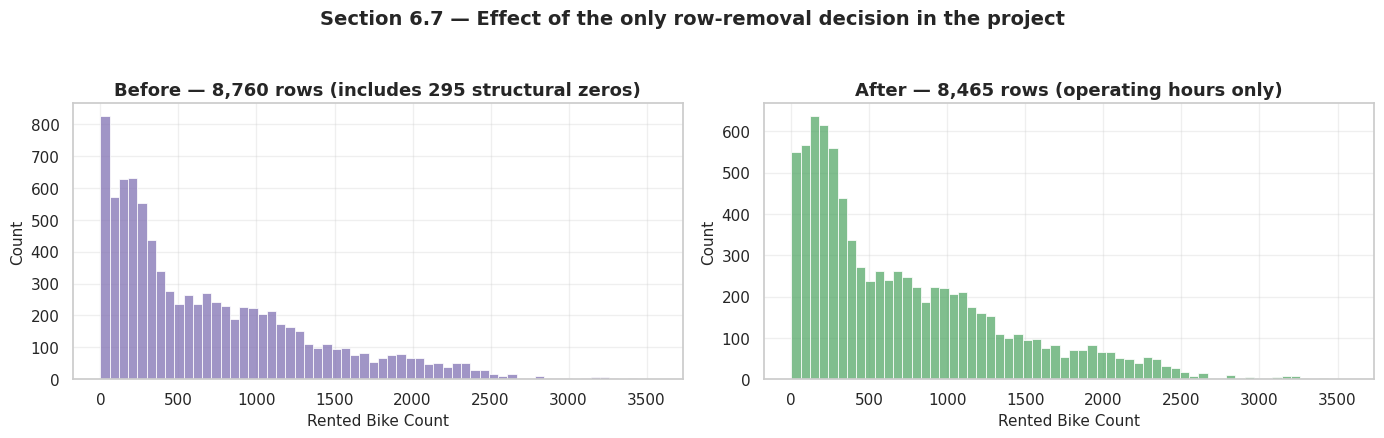

SUMMARY STATISTICS: BEFORE vs AFTER
        Before    After
count  8760.00  8465.00
mean    704.60   729.16
std     645.00   642.35
min       0.00     2.00
25%     191.00   214.00
50%     504.50   542.00
75%    1065.25  1084.00
max    3556.00  3556.00


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

sns.histplot(bike_df[TARGET], bins=60, ax=axes[0], color="#8172B3")
axes[0].set_title(f"Before — {len(bike_df):,} rows (includes 295 structural zeros)")
axes[0].set_xlabel("Rented Bike Count")

sns.histplot(df[TARGET], bins=60, ax=axes[1], color="#55A868")
axes[1].set_title(f"After — {len(df):,} rows (operating hours only)")
axes[1].set_xlabel("Rented Bike Count")

fig.suptitle("Section 6.7 — Effect of the only row-removal decision in the project",
             y=1.04, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_outlier_before_after", fig)
plt.show()

section("SUMMARY STATISTICS: BEFORE vs AFTER")
print(pd.DataFrame({
    "Before": bike_df[TARGET].describe(),
    "After": df[TARGET].describe(),
}).round(2).to_string())

**Interpretation.** The mean rises from 704.6 to 729.2 and the minimum moves
from 0 to 2, but the standard deviation (645 → 642), the quartiles and the
maximum are all essentially unchanged. We removed a
spike of administrative zeros, not a slice of the demand distribution. The
modelling problem is now cleanly defined: *given that the system is open, how
many bikes get rented this hour?*

---
## Handover to Notebook 05

In [10]:
save_artifact(df, "reg_04_cleaned")

print(f"\nFinal shape passed forward: {df.shape}")
print("\nNotebook 04 complete.")
print("Next: 05_regression_feature_engineering.ipynb")

[saved]  artifacts/reg_04_cleaned.joblib

Final shape passed forward: (8465, 13)

Notebook 04 complete.
Next: 05_regression_feature_engineering.ipynb
